# A/B test design: do ads increase site visits? (pre-registration)

Author: Anastasia Kalugina

## 1. Goal

Write down the plan of the analysis **before looking at any result of the
treatment group**: hypotheses, metrics, significance level, minimum detectable
effect, tests, which covariate is used for CUPED and which segments are studied.
Notebook 03 follows this plan and then adds a separate, clearly marked post-hoc
sensitivity section. CACE is mentioned below only as an illustration of how
adherence could be handled; it is not an estimate.

What this notebook uses from the data:

- group sizes (needed for power calculations);
- the **control group only** (base rates, A/A simulation, covariate choice).

It never computes an outcome of the treatment group.

## 2. Context and data

Criteo Uplift Prediction Dataset **v2.1**: one row is one user (not a session, not
an impression). `treatment = 1` means the user was eligible for Criteo ads,
`treatment = 0` is a randomly held-out control group that was not targeted.
Columns: anonymised pre-treatment features `f0`-`f11`, `treatment`, and three
outcomes: `visit` (visited the advertiser site), `conversion` (bought), `exposure`
(the user actually saw an ad).

Why v2.1: the first version had a leak, because incrementality differed between
advertisers and the features partly identified the advertiser. The dataset page
describes this in its erratum and releases an "un-biased" version
(https://ailab.criteo.com/criteo-uplift-prediction-dataset/, checked 2026-10-15).

**Verified:** the dataset page states that it is "constructed by assembling data
resulting from several incrementality tests". The later paper (Diemert et al.,
arXiv:2111.10106) also describes the 13.9 million row collection as coming from
several randomized trials. So the data pools several tests. Randomisation holds
inside each test, but the treatment share and the effect may differ between them
(Simpson's paradox risk, see limitations in notebook 03).

**Important caveat about this data (found later, see notebook 03).** The dataset
page says: "the data has been sub-sampled non-uniformly so that the original
incrementality level cannot be deduced from the dataset". The tests were
re-sampled to a global 85% treatment ratio. So the released sample is a benchmark
for methods, not a faithful record of one experiment.

Citation (required by the data owner): Diemert, E., Betlei, A., Renaudin, C.,
Amini, M.-R. *A Large Scale Benchmark for Uplift Modeling*. AdKDD 2018.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from pa import config, stats  # noqa: E402
from pa.data import register_criteo, register_segment  # noqa: E402
from pa.db import connect, run_sql  # noqa: E402

SEED = config.SEED
ALPHA = config.ALPHA
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}".rstrip("0").rstrip("."))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

if not config.CRITEO_PARQUET.exists():
    raise SystemExit("Run `python -m pa.data download` and `python -m pa.data build`")
con = connect()
register_criteo(con)
print("columns:", [r[0] for r in con.execute("DESCRIBE criteo").fetchall()])

columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


Group sizes come from [`sql/ab/01_group_sizes.sql`](../sql/ab/01_group_sizes.sql).
The unit of randomisation and of analysis is the user, so there is no clustering
to handle.

In [2]:
sizes = run_sql(con, "ab/01_group_sizes").set_index("treatment")
N_C, N_T = int(sizes.n[0]), int(sizes.n[1])
print(sizes)
print(f"\ntotal users: {N_C + N_T:,}")
share_t = N_T / (N_C + N_T)
print(f"treatment share: {share_t:.5f} (design: {config.EXPECTED_TREATMENT_SHARE})")

                  n  share
treatment                 
0           2096937   0.15
1          11882655   0.85

total users: 13,979,592
treatment share: 0.85000 (design: 0.85)


Base rates for the power calculation are taken from the **control group only**:
the untreated rate is exactly what we want to improve, and it contains no
information about the treatment effect. (The plan allowed pooled rates; control
only is cleaner for a pre-registration.)

In [3]:
base = con.execute(
    """
    SELECT COUNT(*) AS n,
           AVG(visit) AS visit_rate,
           AVG(conversion) AS conversion_rate,
           AVG(CASE WHEN visit = 1 THEN conversion END) AS conversion_given_visit,
           AVG(exposure) AS exposure_rate
    FROM criteo WHERE treatment = 0
    """
).df()
P_VISIT = float(base.visit_rate[0])
P_CONV = float(base.conversion_rate[0])
print(base.T.to_string(header=False))

n                      2,096,937
visit_rate              0.038201
conversion_rate         0.001938
conversion_given_visit  0.050721
exposure_rate                  0


**Takeaway.** The control-group base rates above are the anchors for all power
numbers below. The exposure rate in control tells us whether the control group
is really untouched (it should be 0 or close to it).

In [4]:
print(f"Control visit rate: {P_VISIT:.4%}; conversion rate: {P_CONV:.4%}")
print(f"Control exposure rate: {float(base.exposure_rate[0]):.4%}")

Control visit rate: 3.8201%; conversion rate: 0.1938%
Control exposure rate: 0.0000%


## 3. Hypotheses, metrics and decision rules

| Role | Metric | Definition | Test |
|---|---|---|---|
| **Primary** | visit | share of users with `visit = 1` | two-sided z-test, alpha 0.05 |
| Secondary | conversion | share of users with `conversion = 1` | z-test, Holm-adjusted |
| Guardrail | conversion given visit | conversions / visits | **descriptive only**: it conditions on a post-treatment outcome, so the groups being compared are no longer randomised |
| Delivery check | exposure | share of users who actually saw an ad | descriptive; context for adherence (CACE is an illustration only, not an estimate) |

- **H0:** the visit rate is the same in treatment and control. **H1:** ads
  increase it (tested two-sided, so an unexpected decrease is also detected).
- alpha = 0.05 two-sided for the primary metric, power 0.8.
- **Multiplicity.** The primary metric is tested alone at 0.05. One Holm family
  of 9 tests covers the secondary metric and the segments: conversion overall,
  visit in 4 segments, conversion in 4 segments.
- **Analysis population:** intention-to-treat, all users as randomised. CACE
  (effect on users who actually saw an ad) is an illustration only, not an
  estimate.
- **Practical importance.** With millions of users almost any difference is
  "significant". The effect will be judged by its size and interval, not by the
  p-value alone; the reference scale is the relative lifts in the table below.

## 4. Minimum detectable effect and sample size

For the actual group sizes we compute the smallest absolute (and relative) lift
that a two-sided test with alpha 0.05 would detect with 80% power. Then the other
direction: the users needed per group for relative lifts of 1%, 2% and 5%, for
the real 85/15 split and for an equal split. Own formulas from `pa/stats.py`
are used, covered by unit tests (round trip between MDE and sample size).

In [5]:
rows = []
for name, p in [("visit", P_VISIT), ("conversion", P_CONV)]:
    mde_abs = stats.mde_proportion(p, N_C, N_T, alpha=ALPHA, power=0.8)
    rows.append(
        {"metric": name, "base_rate": p, "mde_abs": mde_abs, "mde_rel": mde_abs / p}
    )
mde_table = pd.DataFrame(rows)
mde_table

,metric,base_rate,mde_abs,mde_rel
0,visit,0.038201,0.000404,0.010564
1,conversion,0.001938,0.000094,0.048355


Required users per group for relative lifts of 1%, 2% and 5%.

In [6]:
size_rows = []
for name, p in [("visit", P_VISIT), ("conversion", P_CONV)]:
    for rel in (0.01, 0.02, 0.05):
        n_c85, n_t85 = stats.sample_size_proportion(
            p, rel, ratio=N_T / N_C, alpha=ALPHA, power=0.8
        )
        n_eq, _ = stats.sample_size_proportion(p, rel, alpha=ALPHA, power=0.8)
        size_rows.append(
            {
                "metric": name,
                "relative_mde": rel,
                "n_control_at_actual_split": n_c85,
                "n_treatment_at_actual_split": n_t85,
                "n_per_group_equal_split": n_eq,
                "enough_users": n_c85 <= N_C,
            }
        )
size_table = pd.DataFrame(size_rows)
size_table

,metric,relative_mde,n_control_at_actual_split,n_treatment_at_actual_split,n_per_group_equal_split,enough_users
0,visit,0.01,2339142,13255151,3971252,False
1,visit,0.02,588349,3333976,997554,True
2,visit,0.05,95841,543099,161882,True
3,conversion,0.01,47868281,271253866,81263547,False
4,conversion,0.02,12042898,68243157,20416762,False
5,conversion,0.05,1963203,11124824,3315100,True


A one-line reading of the two tables above, built from their values.

In [7]:
v = mde_table.iloc[0]
c = mde_table.iloc[1]
print(
    f"Takeaway: with {N_C:,} control and {N_T:,} treatment users the test detects "
    f"a visit lift of {v.mde_abs:.4%} points ({v.mde_rel:.2%} relative) and a "
    f"conversion lift of {c.mde_abs:.5%} points ({c.mde_rel:.2%} relative) "
    f"with 80% power."
)
short = size_table[~size_table.enough_users]
if len(short):
    print("Not enough users for:", short[["metric", "relative_mde"]].values.tolist())
else:
    print("The data is large enough for every row of the table above.")

Takeaway: with 2,096,937 control and 11,882,655 treatment users the test detects a visit lift of 0.0404% points (1.06% relative) and a conversion lift of 0.00937% points (4.84% relative) with 80% power.
Not enough users for: [['visit', 0.01], ['conversion', 0.01], ['conversion', 0.02]]


**Reading the table.** A relative MDE far below 1% means the test is
over-powered: a statistically significant but commercially irrelevant lift is
possible, which is why the decision rule above looks at the interval, not at the
p-value. Conversion is rarer than visits, so its MDE is larger in relative terms.

## 5. Sample ratio mismatch (SRM) plan

*Added after the stress test: because Criteo re-sampled every test to exactly 85%,
the SRM check is **not informative** for this dataset (it cannot detect broken
randomisation). The pre-registered check is kept and its numbers are reported.*

The SRM check is an **informative data-quality check**. We report the observed
treatment share, the chi-square statistic and the p-value against the nominal 0.85.

Two things make the p-value a poor stop rule here:

- the dataset page publishes the ratio only as `.85` (two decimals), so the true
  design share is not known exactly;
- the data pool several tests (see section 2), whose own splits may differ a bit.

With about 14 million users, any small deviation gives a tiny p-value. So p alone
does not stop the analysis; the observed share is reported as it is, and a small
p-value comes with a caveat.

**Stop rule (pre-registered):** if the observed share differs from 0.85 by more
than **1 percentage point**, notebook 03 raises an error and stops. The number is a
pragmatic choice, not a statistical result: it is twice the largest error that
publishing the share to two decimals can explain (0.5 points), so a deviation beyond
it needs an explanation before any outcome is read.

In [8]:
SRM_STOP_DEVIATION = 0.01
srm = stats.srm_check(N_C, N_T, config.EXPECTED_TREATMENT_SHARE)
deviation = abs(srm.observed_share - srm.expected_share)
print(f"observed treatment share: {srm.observed_share:.6f} (nominal 0.85)")
print(f"chi2 = {srm.chi2:.2f}, p = {srm.p_value:.3g}")
print(f"deviation from 0.85: {deviation:.4%} points")
print(f"stop rule: more than {SRM_STOP_DEVIATION:.0%}")
print(
    "Takeaway: "
    + (
        "the deviation exceeds the stop rule, do not continue."
        if deviation > SRM_STOP_DEVIATION
        else "the deviation is within the stop rule; a small p-value would be a "
        "caveat (approximate nominal share, pooled tests), not a reason to stop."
    )
)

observed treatment share: 0.850000 (nominal 0.85)
chi2 = 0.00, p = 0.999
deviation from 0.85: 0.0000% points
stop rule: more than 1%
Takeaway: the deviation is within the stop rule; a small p-value would be a caveat (approximate nominal share, pooled tests), not a reason to stop.


## 6. Choice of the test

Visit and conversion are 0/1 variables, the groups are large and independent.

- **Two-proportion z-test** (pooled standard error for the p-value, unpooled for
  the confidence interval). With this many users it gives the same answer as
  Welch's t-test on the 0/1 values (the formulas coincide up to a negligible
  difference in the variance estimate), and its interval is easy to read.
- **Mann-Whitney is not used.** On a 0/1 variable the ranks take two values and
  almost everything is a tie; the test then compares the shares in a roundabout way
  and its "effect" is a probability of superiority, which is harder to interpret
  than a difference in rates.
- **Bootstrap** (multinomial resampling of the four visit x conversion cells, 2000
  draws, seed 42) is a check on the analytical interval, not a replacement.
- **CUPED** with one pre-treatment feature to reduce variance (section 8).
- **Multiplicity:** Holm correction for the family in section 3.

## 7. A/A simulation: does the test hold its 5% error rate?

Both "groups" are random halves of the **control** group, so there is no effect
by construction. A correct test rejects in about 5% of the runs. Each run uses
200,000 users.

A first run with 1,000 runs gave 0.065, outside the +/- 0.014 range expected for
1,000 runs (binomial standard error 0.69 points). One run cannot separate noise
from a real problem, so the simulation was repeated with **10,000 runs** (range
+/- 0.004).

What this checks: that the **test procedure** (the z-test on sampled halves) holds
its error rate. It does **not** validate the randomisation of the dataset: both
halves come from the same control group, so a flawed treatment assignment would not
show up here.

In [9]:
y_control = con.execute("SELECT visit FROM criteo WHERE treatment = 0").fetchnumpy()[
    "visit"
]
N_ITER = 10_000
fpr_visit = stats.aa_false_positive_rate(
    y_control, n_iter=N_ITER, sample_size=200_000, seed=SEED, alpha=ALPHA
)
se = (ALPHA * (1 - ALPHA) / N_ITER) ** 0.5
print(f"A/A false positive rate (visit): {fpr_visit:.3f}")
print(f"expected {ALPHA} +/- {1.96 * se:.3f} (95% range for {N_ITER:,} runs)")
if abs(fpr_visit - ALPHA) <= 1.96 * se:
    print("Takeaway: the test holds its nominal error rate on this data.")
else:
    print(
        f"Takeaway: the rejection rate is {fpr_visit - ALPHA:+.4f} away from "
        f"{ALPHA}, outside the range expected for a correct test with "
        f"{N_ITER:,} independent runs. The runs overlap (all draw from the same "
        "control users), so the binomial range is only approximate; a small real "
        "problem cannot be excluded. Reported, not explained away."
    )

A/A false positive rate (visit): 0.054
expected 0.05 +/- 0.004 (95% range for 10,000 runs)
Takeaway: the rejection rate is +0.0045 away from 0.05, outside the range expected for a correct test with 10,000 independent runs. The runs overlap (all draw from the same control users), so the binomial range is only approximate; a small real problem cannot be excluded. Reported, not explained away.


## 8. CUPED covariate and segmentation feature

CUPED subtracts the part of the outcome that a pre-treatment variable predicts.
The features `f0`-`f11` are anonymised and measured before treatment. The choice
is made **on the control group only**: the feature with the largest absolute
correlation with `visit` among those whose quartiles do not collapse because of
ties (every quartile must hold 10-40% of the control users). The same feature
defines the segments (quartiles), so that there is exactly one pre-chosen split and
no search over segments.

**Retrospective note (added after a stress test of this analysis).** This rule had
two flaws. (1) It coupled the CUPED covariate with the segmentation feature, which
are different jobs. (2) It treated all 12 features as numbers, but according to the
paper (Diemert et al., arXiv:2111.10106, Table 2) f1, f3, f4, f5, f6, f8, f9 and f11
are *hashed categorical* features; only f0, f2, f7 and f10 are continuous. A
correlation of a hashed category code with `visit` is not meaningful. The
pre-registered choice (f0, a continuous feature) is kept unchanged, and the
corrected adjustments are shown as a post-hoc analysis in notebook 03.

In [10]:
cols = ", ".join(config.FEATURES)
ctrl = con.execute(f"SELECT visit, {cols} FROM criteo WHERE treatment = 0").fetchnumpy()
y_ctrl = ctrl["visit"].astype(np.float64)
corr = pd.Series(
    {
        f: float(np.corrcoef(ctrl[f].astype(np.float64), y_ctrl)[0, 1])
        for f in config.FEATURES
    }
)
print(corr.to_string())


def quartile_shares(values):
    # share of control users per quartile (cut points and <= as in the SQL)
    q = np.quantile(values.astype(np.float64), [0.25, 0.5, 0.75])
    if not (q[0] < q[1] < q[2]):
        return None
    cum = [(values <= c).sum() for c in q] + [len(values)]
    return np.diff([0, *cum]) / len(values)


candidates = []
for f in corr.abs().sort_values(ascending=False).index:
    shares = quartile_shares(ctrl[f])
    ok = bool(shares is not None and shares.min() >= 0.10 and shares.max() <= 0.40)
    candidates.append({"feature": f, "abs_corr": abs(corr[f]), "quartiles_ok": ok})
cand = pd.DataFrame(candidates)
print(cand.to_string(index=False))
CUPED_FEATURE = cand[cand.quartiles_ok].feature.iloc[0]
rho = corr[CUPED_FEATURE]
print("(features whose quartiles collapse because of ties are skipped)")
print(f"\nchosen feature: {CUPED_FEATURE}, correlation in control: {rho:.4f}")
print(f"expected variance reduction (rho^2): {rho**2:.4%}")

f0    -0.115668
f1     0.074241
f2    -0.031302
f3    -0.130747
f4     0.262995
f5    -0.090678
f6    -0.073533
f7     0.058939
f8    -0.428864
f9     0.470192
f10    0.193483
f11   -0.216728
feature  abs_corr  quartiles_ok
     f9  0.470192         False
     f8  0.428864         False
     f4  0.262995         False
    f11  0.216728         False
    f10  0.193483         False
     f3  0.130747         False
     f0  0.115668          True
     f5  0.090678         False
     f1  0.074241         False
     f6  0.073533         False
     f7  0.058939         False
     f2  0.031302         False
(features whose quartiles collapse because of ties are skipped)

chosen feature: f0, correlation in control: -0.1157
expected variance reduction (rho^2): 1.3379%


Bar chart of the correlations printed above.

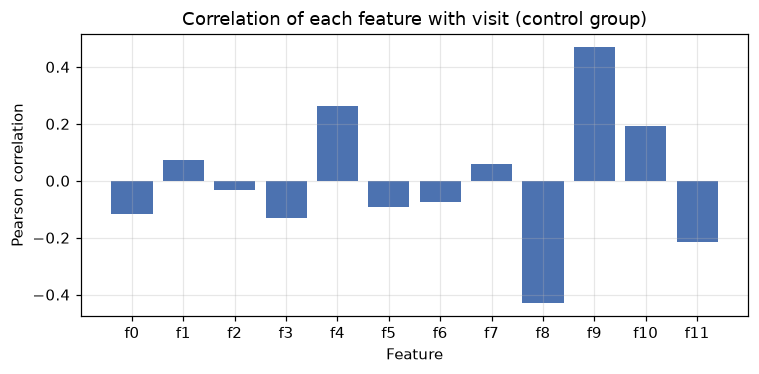

In [11]:
del ctrl
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(corr.index, corr.values, color="#4c72b0")
ax.set_title("Correlation of each feature with visit (control group)")
ax.set_xlabel("Feature")
ax.set_ylabel("Pearson correlation")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "criteo_feature_correlation.png", dpi=130)
plt.show()

**Takeaway.** The chosen feature and its correlation are printed above. CUPED can
only remove about rho squared of the variance, so if the correlation is weak the
gain will be small; that is a property of anonymised features, not a flaw of the
method. The choice is saved to `docs/preregistration.json` (tracked in git) for notebook 03.

## 9. Segments

Quartiles of the chosen feature (cut points from `percentile_cont`, see
[`sql/ab/04_segment_metrics.sql`](../sql/ab/04_segment_metrics.sql)). Segment
results are **exploratory**: 4 segments for visit and 4 for conversion, all inside
the Holm family from section 3. Feature values are anonymised, so segments cannot
be described in business terms.

In [12]:
register_segment(con, CUPED_FEATURE)
seg_check = run_sql(con, "ab/04_segment_metrics")
sizes_by_q = seg_check.groupby("quartile")["n"].sum()
print("users per quartile (group sizes only, no outcomes):")
print(sizes_by_q.to_string())
assert len(sizes_by_q) == 4 and (sizes_by_q > 0).all(), "quartiles collapsed"
design = {
    "cuped_feature": CUPED_FEATURE,
    "segment_feature": CUPED_FEATURE,
    "alpha": ALPHA,
    "srm_alarm_p": 0.001,
    "srm_stop_deviation": SRM_STOP_DEVIATION,
    "n_boot": 2000,
    "holm_family_size": 9,
    "control_visit_rate": P_VISIT,
    "control_conversion_rate": P_CONV,
}
if config.DESIGN_FILE.exists():
    saved = json.loads(config.DESIGN_FILE.read_text())
    assert saved["cuped_feature"] == CUPED_FEATURE, "pre-registered feature changed"
    assert saved["segment_feature"] == CUPED_FEATURE
    design = saved
    print("pre-registration file exists and matches: kept unchanged")
else:
    config.DESIGN_FILE.parent.mkdir(parents=True, exist_ok=True)
    config.DESIGN_FILE.write_text(json.dumps(design, indent=2) + "\n")
    print("saved pre-registered choices to", config.DESIGN_FILE)
print(json.dumps(design, indent=2))

users per quartile (group sizes only, no outcomes):
quartile
1    3705545
2    3284251
3    3494900
4    3494896
pre-registration file exists and matches: kept unchanged
{
  "cuped_feature": "f0",
  "segment_feature": "f0",
  "alpha": 0.05,
  "srm_alarm_p": 0.001,
  "srm_stop_deviation": 0.01,
  "n_boot": 2000,
  "holm_family_size": 9,
  "control_visit_rate": 0.03820095691954503,
  "control_conversion_rate": 0.0019375880152813366
}


## 10. Summary of the plan

- Unit: user; population: all users as randomised (ITT).
- Primary: visit, two-sided z-test, alpha 0.05; bootstrap and CUPED as checks.
- Secondary and segments: one Holm family of 9 tests.
- Guardrail (conversion given visit): descriptive only.
- Before the outcome: SRM check (informative; stop if the share is more than
  1 point away from 0.85), covariate balance, exposure in both groups.
- Decision: judged by effect size and interval against the MDE table, not by
  significance alone.

Notebook 03 executes this plan, then adds a clearly marked post-hoc section.

**Notes on this pre-registration.** It is procedural, not blind: the author could
not be blind to published results on this dataset (Criteo's papers and many public
benchmarks report uplift on it). The choices above were made before running
notebook 03 on the treatment group, but the author knew the dataset.

## 11. Sources

- Criteo AI Lab, Criteo Uplift Prediction Dataset (v2.1, erratum, key figures):
  https://ailab.criteo.com/criteo-uplift-prediction-dataset/ (checked 2026-10-15).
- Diemert, E., Betlei, A., Renaudin, C., Amini, M.-R. A Large Scale Benchmark for
  Uplift Modeling. AdKDD 2018.
- Diemert, E., Betlei, A., Renaudin, C., Amini, M.-R., Gregoir, T., Rahier, T.
  A Large Scale Benchmark for Individual Treatment Effect Prediction and Uplift
  Modeling. arXiv:2111.10106.
- Deng, A., Xu, Y., Kohavi, R., Walker, T. Improving the sensitivity of online
  controlled experiments by utilizing pre-experiment data (CUPED). WSDM 2013.